# Sales & Inflation Analysis with Python (Pandas)
A beginner-friendly data analysis project. It creates a **sample** monthly sales dataset, cleans it, analyses trends, and adjusts sales for inflation, a classic economics idea (nominal vs real values).

**Run:** Open in Google Colab, then Runtime > Run all. No files needed.
**Tools:** Python, Pandas, NumPy, Matplotlib

## Step 1: Create sample data
The data is made up for practice (not a real company). Some values are deliberately left missing so we can practise cleaning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
months = pd.date_range('2024-01-01', periods=24, freq='MS')
products = ['Rice', 'Mobile Phones', 'Shirts', 'Cookware']
rows = []
for m in months:
    for p in products:
        base = {'Rice': 50000, 'Mobile Phones': 200000, 'Shirts': 80000, 'Cookware': 60000}[p]
        trend = 1 + 0.01 * months.get_loc(m)
        rows.append([m, p, int(base * trend * np.random.uniform(0.8, 1.2))])
df = pd.DataFrame(rows, columns=['Month', 'Product', 'Sales_INR'])
df.loc[df.sample(4, random_state=1).index, 'Sales_INR'] = np.nan   # missing values
df.head()

,Month,Product,Sales_INR
0,2024-01-01,Rice,47490.0
1,2024-01-01,Mobile Phones,236057.0
2,2024-01-01,Shirts,87423.0
3,2024-01-01,Cookware,62367.0
4,2024-02-01,Rice,43551.0


## Step 2: Inspect and clean

In [2]:
print(df.shape)
print(df.isna().sum())
# Fill missing sales with the average sales of that same product
df['Sales_INR'] = df.groupby('Product')['Sales_INR'].transform(lambda s: s.fillna(s.mean()))
print('Missing after cleaning:', df['Sales_INR'].isna().sum())

(96, 3)
Month        0
Product      0
Sales_INR    4
dtype: int64
Missing after cleaning: 0


## Step 3: Analyse

In [3]:
total_by_product = df.groupby('Product')['Sales_INR'].sum().sort_values(ascending=False)
print(total_by_product)

monthly = df.groupby('Month')['Sales_INR'].sum()
growth = monthly.pct_change() * 100
print('\nAverage monthly growth: %.2f%%' % growth.mean())
print('Best month:', monthly.idxmax().strftime('%b %Y'))

Product
Mobile Phones    5.324058e+06
Shirts           2.110688e+06
Cookware         1.642145e+06
Rice             1.316393e+06
Name: Sales_INR, dtype: float64

Average monthly growth: 1.42%
Best month: Dec 2025


## Step 4: Visualise

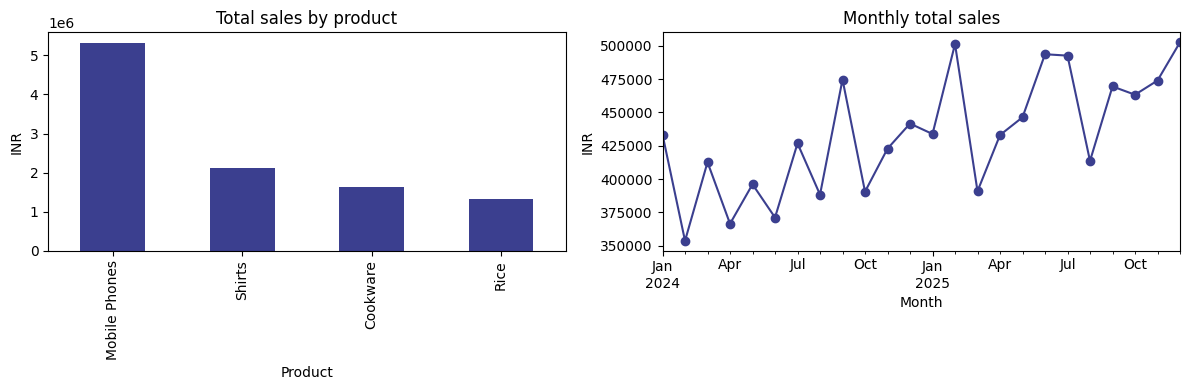

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
total_by_product.plot(kind='bar', ax=ax[0], color='#3B3F8F', title='Total sales by product')
ax[0].set_ylabel('INR')
monthly.plot(ax=ax[1], marker='o', color='#3B3F8F', title='Monthly total sales')
ax[1].set_ylabel('INR')
plt.tight_layout(); plt.show()

## Step 5: Economics angle, nominal vs real sales
Prices rise over time, so a rise in sales may just be inflation. We assume **5% annual inflation** (an assumption for practice; replace it with real CPI data from the MoSPI website to make it stronger).
Real sales = Nominal sales / price index

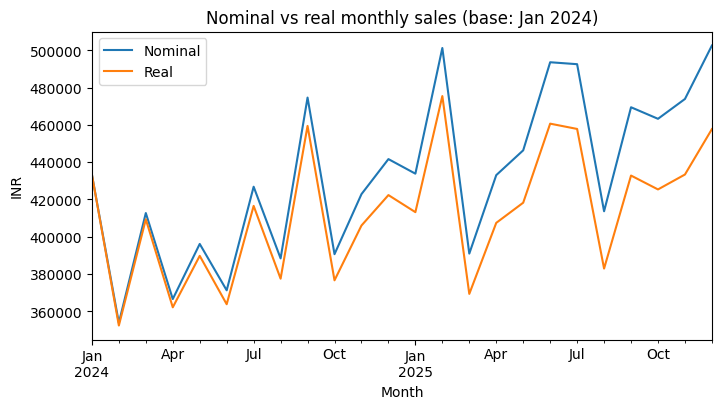

Nominal growth Jan24 to Dec25: 16.0%
Real growth Jan24 to Dec25:    5.6%


In [5]:
annual_inflation = 0.05
monthly_rate = (1 + annual_inflation) ** (1/12) - 1
price_index = (1 + monthly_rate) ** np.arange(len(monthly))

real = monthly.values / price_index
compare = pd.DataFrame({'Nominal': monthly.values, 'Real': real}, index=monthly.index)
compare.plot(figsize=(8, 4), title='Nominal vs real monthly sales (base: Jan 2024)')
plt.ylabel('INR'); plt.show()

print('Nominal growth Jan24 to Dec25: %.1f%%' % ((monthly.iloc[-1]/monthly.iloc[0]-1)*100))
print('Real growth Jan24 to Dec25:    %.1f%%' % ((real[-1]/real[0]-1)*100))


## Limitations
Data is simulated and the inflation rate is assumed.